# 02 — Model Development
**GameGuard AI · Toxicity classification**

**Goal:** Train a clear, reproducible **TF-IDF + Logistic Regression baseline** for classifying a gaming message as **Not Toxic (0)** or **Toxic (1)**.

**Inputs:** `data/processed/train.csv` and `data/processed/validation.csv`  
**Output:** `models/tfidf_logistic_regression.joblib`

In this notebook, we will:
1. Load and verify the processed data.
2. Train three easy-to-compare Logistic Regression configurations.
3. Compare their performance on the validation set.
4. Inspect prediction errors and save the best baseline.

**Important:** The test set stays untouched. We will use it only for final evaluation. The Qwen experiments will come after this baseline.

## 1. Load the prepared datasets
The previous notebook already cleaned the messages, converted the labels to binary classes, and created separate data splits. We reuse those CSV files rather than repeating preprocessing here.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

# Locate the project root when running from either / or /notebooks.
ROOT = next(
    (
        folder for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "data" / "processed" / "train.csv").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Missing data/processed/train.csv. Run 01_Data_Preprocessing.ipynb first."
    )

DATA_DIR = ROOT / "data" / "processed"
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")

for name, part in (("Train", train_df), ("Validation", val_df)):
    if not {"message", "label"}.issubset(part.columns):
        raise ValueError(f"{name} data must contain 'message' and 'label'.")
    if part[["message", "label"]].isna().any().any():
        raise ValueError(f"{name} data contains missing messages or labels.")
    if part["message"].astype(str).str.strip().eq("").any():
        raise ValueError(f"{name} data contains empty messages.")
    if set(part["label"].unique()) != {0, 1}:
        raise ValueError(f"{name} data must contain both binary labels 0 and 1.")

# Prevent identical messages from appearing in both splits.
train_keys = set(train_df["message"].astype(str).str.casefold())
val_keys = set(val_df["message"].astype(str).str.casefold())
assert train_keys.isdisjoint(val_keys), "Train/validation message overlap detected."

X_train, y_train = train_df["message"], train_df["label"].astype(int)
X_val, y_val = val_df["message"], val_df["label"].astype(int)

summary = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Messages": [len(train_df), len(val_df)],
    "Toxic (%)": [f"{y_train.mean():.1%}", f"{y_val.mean():.1%}"],
})
display(summary)

,Dataset,Messages,Toxic (%)
0,Training,19196,24.3%
1,Validation,4113,24.3%


## 2. Define the baseline models
**TF-IDF** transforms text into numerical features. **Logistic Regression** learns to predict the probability of the Toxic class from those features.

We compare three configurations, changing one meaningful choice at a time:

| Model | Text features | Class weighting | Reason to test |
|---|---|---|---|
| Word TF-IDF | Words and two-word phrases | None | Simple reference baseline |
| Word TF-IDF (balanced) | Words and two-word phrases | Balanced | Helps counter the larger Not Toxic class |
| Character TF-IDF (balanced) | Character groups of length 3–5 | Balanced | May handle spelling errors and gaming slang better |

We use a **scikit-learn Pipeline** so TF-IDF is fitted **only on training messages**. The validation set is used only for predictions and model comparison.

In [2]:
def build_model(feature_type: str, balanced: bool) -> Pipeline:
    """Create a reproducible TF-IDF + Logistic Regression pipeline."""
    if feature_type == "word":
        vectorizer = TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            token_pattern=r"(?u)\b\w+\b",  # Retain one-letter chat words like 'u'.
            min_df=2,
            max_features=60_000,
            sublinear_tf=True,
        )
    elif feature_type == "character":
        vectorizer = TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
            max_features=100_000,
            sublinear_tf=True,
        )
    else:
        raise ValueError("feature_type must be 'word' or 'character'.")

    classifier = LogisticRegression(
        max_iter=1000,
        solver="liblinear",
        class_weight="balanced" if balanced else None,
        random_state=RANDOM_STATE,
    )
    return Pipeline([("tfidf", vectorizer), ("classifier", classifier)])


experiments = {
    "Word TF-IDF": build_model("word", balanced=False),
    "Word TF-IDF (balanced)": build_model("word", balanced=True),
    "Character TF-IDF (balanced)": build_model("character", balanced=True),
}

print(f"Ready to train {len(experiments)} baseline configurations.")

Ready to train 3 baseline configurations.


## 3. Train and compare on validation data
We track **accuracy** and the **Toxic-class precision, recall, and F1-score**. Accuracy alone can be misleading because most messages are Not Toxic.

- **Precision (Toxic):** Of the messages flagged as toxic, how many really are toxic?
- **Recall (Toxic):** Of all toxic messages, how many did we catch?
- **F1 (Toxic):** Balances precision and recall.

We will select the baseline by **Toxic-class F1**, using accuracy as a tie-breaker. This selection rule is defined *before* looking at the results.

In [3]:
trained_models = {}
validation_predictions = {}
results = []

for name, model in experiments.items():
    print(f"Training: {name}")
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    trained_models[name] = model
    validation_predictions[name] = predictions
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Toxic precision": precision_score(y_val, predictions, pos_label=1, zero_division=0),
        "Toxic recall": recall_score(y_val, predictions, pos_label=1, zero_division=0),
        "Toxic F1": f1_score(y_val, predictions, pos_label=1, zero_division=0),
        "Macro F1": f1_score(y_val, predictions, average="macro", zero_division=0),
    })

comparison = (
    pd.DataFrame(results)
    .sort_values(["Toxic F1", "Accuracy"], ascending=False)
    .reset_index(drop=True)
)

# Show percentages while keeping the original numeric metrics for sorting.
display(comparison.style.format({
    "Accuracy": "{:.2%}",
    "Toxic precision": "{:.2%}",
    "Toxic recall": "{:.2%}",
    "Toxic F1": "{:.2%}",
    "Macro F1": "{:.2%}",
}))

best_name = comparison.loc[0, "Model"]
best_model = trained_models[best_name]
best_predictions = validation_predictions[best_name]
print(f"Selected baseline: {best_name}")

Training: Word TF-IDF
Training: Word TF-IDF (balanced)
Training: Character TF-IDF (balanced)


,Model,Accuracy,Toxic precision,Toxic recall,Toxic F1,Macro F1
0,Character TF-IDF (balanced),88.89%,75.45%,80.36%,77.83%,85.21%
1,Word TF-IDF (balanced),85.63%,70.21%,70.84%,70.52%,80.51%
2,Word TF-IDF,85.56%,86.33%,48.10%,61.78%,76.44%


Selected baseline: Character TF-IDF (balanced)


## 4. Understand the errors
A confusion matrix shows how often the model gets each class right or wrong. Pay special attention to:

- **False positives:** Safe messages incorrectly classified as Toxic.
- **False negatives:** Toxic messages incorrectly classified as Not Toxic.

These examples help us understand where the model struggles, rather than judging it only by one score.

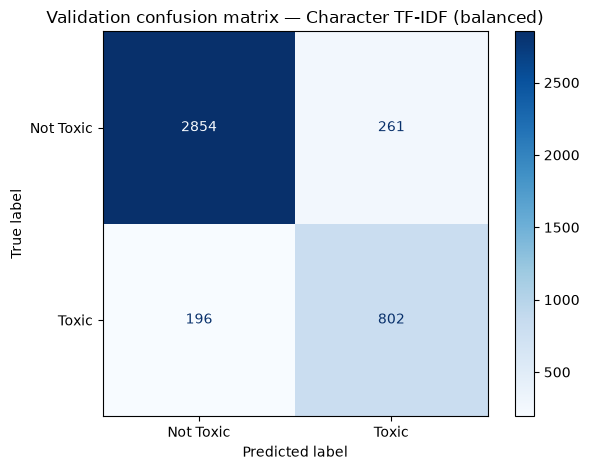

False positives: 261
False negatives: 196

Sample false positives (safe messages flagged as toxic):


,message
0,arty caeveron
15,I didnt die
24,i hate this map for the GC
53,klingon
59,jebany debil



Sample false negatives (toxic messages that were missed):


,message
25,х** вам а не победу
77,"nice help on the hill, nobs"
108,that manti
113,degenerate
126,"dude, report yourseld aswell"


In [4]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    best_predictions,
    labels=[0, 1],
    display_labels=["Not Toxic", "Toxic"],
    cmap="Blues",
    values_format="d",
)
plt.title(f"Validation confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

errors = val_df[["message", "label"]].copy()
errors["predicted"] = best_predictions

false_positives = errors[(errors["label"] == 0) & (errors["predicted"] == 1)]
false_negatives = errors[(errors["label"] == 1) & (errors["predicted"] == 0)]

print(f"False positives: {len(false_positives):,}")
print(f"False negatives: {len(false_negatives):,}")

print("\nSample false positives (safe messages flagged as toxic):")
display(false_positives[["message"]].head(5))

print("\nSample false negatives (toxic messages that were missed):")
display(false_negatives[["message"]].head(5))

## 5. Save the selected baseline
We save the **whole pipeline** (TF-IDF + Logistic Regression). This matters: the backend must apply the **same text-to-feature transformation** that the model used during training.

The saved model is a **baseline artifact**, not yet the final GameGuard AI model. We may choose a different model after comparing it with Qwen.

In [5]:
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "tfidf_logistic_regression.joblib"
joblib.dump(best_model, MODEL_PATH)

# Confirm the saved pipeline can be loaded and produces the same predictions.
reloaded_model = joblib.load(MODEL_PATH)
assert (reloaded_model.predict(X_val) == best_predictions).all()

print(f"Saved baseline: {MODEL_PATH.relative_to(ROOT)}")
print(f"Validation accuracy: {comparison.loc[0, 'Accuracy']:.2%}")
print(f"Validation Toxic F1: {comparison.loc[0, 'Toxic F1']:.2%}")

Saved baseline: models\tfidf_logistic_regression.joblib
Validation accuracy: 88.89%
Validation Toxic F1: 77.83%


## 6. Conclusions and next steps
After running the notebook, record what you learned from **your actual validation output**:

- **Best baseline:** Refer to the selected model printed above.
- **Accuracy vs. Toxic F1:** Was the most accurate configuration also the best at detecting toxicity?
- **Error analysis:** What types of messages caused false positives or false negatives?
- **Limitation:** These World of Tanks messages have no conversation history. We cannot test the impact of previous chat messages using this dataset alone.

**Next:** Evaluate the instruction-tuned Qwen model with and without conversational context, using suitable conversation-level data. Keep `data/processed/test.csv` unseen until final evaluation. A high validation accuracy is not proof that the model works equally well in other games.